# Five-fold YOLO / BCS evaluation
This notebook reloads saved models; it does **not retrain** them. It is tailored to `YOLO_k_1_BCS.ipynb` and the manifests that notebook saves beside each detector run.

This version loads all five saved cow detectors and all five BCS classifiers trained with `YOLO_k_1_BCS.ipynb`. It evaluates the full pipeline and the classifier on expert crops, without retraining. Complete classifier training for folds 1–5 before running all cells. The preflight check lists any missing weights or manifests before inference starts.

Run in Colab with your Drive mounted. Expert BCS labels and held-out animal assignments are read from the saved manifests; no Excel upload is required.

## Interpretation of the success criteria
On photos whose **expert** BCS is in **[3.25, 3.50]**, report these separately:

- MAE ≤ 0.25 BCS points: $\mathrm{MAE}=\frac1n\sum_i|\hat y_i-y_i|$.
- RMSE ≤ 0.35 BCS points: $\mathrm{RMSE}=\sqrt{\frac1n\sum_i(\hat y_i-y_i)^2}$.
- Tolerated hit rate ≥ 80%: $100\frac{\#\{i:|\hat y_i-y_i|\leq0.25\}}{N}$.

Here, `N` includes every eligible photo; missing predictions count as misses. MAE/RMSE use the `n` available predictions and are explicitly conditional when coverage is incomplete. The overall verdict is **incomplete** if any prediction is missing, even if the numerical thresholds pass. This is a conservative reporting convention, not an extra numerical criterion supplied by you.

**Narrow-range warning:** if all true and predicted scores are either 3.25 or 3.50, any error is at most 0.25. MAE, RMSE and tolerated accuracy will automatically meet these limits with complete predictions. Exact accuracy is therefore also shown. Predictions are never clipped to the target range. Confirm whether your intended range is 3.25–3.50 or a wider range before interpreting success.

## Evaluation design
Each fold model sees only its own held-out ranch cows. External training images are excluded. The pooled out-of-fold (OOF) result combines all five held-out prediction sets; it is not the arithmetic mean of fold RMSEs. Comparing folds describes variability across different validation sets; it does not establish which model is best on a common test set. These folds were also used for checkpoint selection in training, so a separate untouched test set is preferable for final confirmation.

Two BCS modes are reported when classifiers exist:
1. `pipeline`: detector crop → classifier (the deployment-oriented result).
2. `expert_crop`: expert bounding box → classifier (classifier diagnostic).

The primary metrics weight photos equally. Supplementary cow-level metrics first average predicted BCS over a cow's photos; they weight cows equally but can hide opposite photo errors. Worst photo errors per cow are exported separately. RMSE penalizes large errors, but does not guarantee a maximum error for every animal.


In [4]:
%pip install -q ultralytics pandas pillow pillow-heif matplotlib tqdm
from google.colab import drive
from pathlib import Path
import math, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
from tqdm.auto import tqdm
import torch, ultralytics
from ultralytics import YOLO
from IPython.display import display
register_heif_opener()
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Configuration
Paths match the detector and BCS classifier training notebook. Each classifier uses 224-pixel inputs and is paired with the detector that excluded the same fold. Set exact paths here if you renamed any completed training runs. Backup directories are not used.


In [5]:
BASE = Path('/content/drive/MyDrive/lecheros/Dataset')
RESULTS = BASE / 'bcs_training'
FOLDS = [1, 2, 3, 4, 5]
DETECTOR_PATHS = {f: RESULTS / f'detector_fold_{f}' / 'weights/best.pt' for f in FOLDS}
MANIFEST_PATHS = {f: DETECTOR_PATHS[f].parent.parent / 'manifest.csv' for f in FOLDS}
CLASSIFIER_PATHS = {f: RESULTS / f'classifier_fold_{f}' / 'weights/best.pt' for f in FOLDS}
CLASSIFIER_MANIFESTS = {f: CLASSIFIER_PATHS[f].parent.parent / 'manifest.csv' for f in FOLDS}

TARGET_RANGE = (3.25, 3.50)  # Inclusive; select using expert BCS, not predictions.
TOLERANCE, MAE_LIMIT, RMSE_LIMIT, HIT_LIMIT = 0.25, 0.25, 0.35, 80.0
DET_CONF, DET_IMGSZ, CLS_IMGSZ = 0.25, 640, 224
# Set CLS_IMGSZ to the size used by your classifier. Fix settings before evaluation.
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
OUT = RESULTS / 'evaluation_5fold_bcs'
OUT.mkdir(parents=True, exist_ok=True)
# Optional path remapping if photos/labels moved since training:
OLD_PREFIX = None  # e.g. '/content/drive/MyDrive/old_dataset'
NEW_PREFIX = str(BASE)

def resolve_path(value):
    value = str(value)
    if OLD_PREFIX and (value == OLD_PREFIX or value.startswith(OLD_PREFIX + '/')):
        value = NEW_PREFIX + value[len(OLD_PREFIX):]
    return Path(value)

print('Ultralytics:', ultralytics.__version__, '| Device:', DEVICE)


Ultralytics: 8.4.202 | Device: 0


## 2. Validate held-out splits
This checks saved metadata, cow separation and file availability. It cannot prove how a classifier was trained; verify its training split yourself. The original notebook skipped photos without labels. Consequently, this evaluation covers the saved, labeled-photo cohort, not every photo originally collected.


In [6]:
# Require all five trained pairs rather than silently omitting BCS predictions.
missing_files = []
for f in FOLDS:
    for role, path in [('detector', DETECTOR_PATHS[f]),
                       ('classifier', CLASSIFIER_PATHS[f]),
                       ('detector manifest', MANIFEST_PATHS[f]),
                       ('classifier manifest', CLASSIFIER_MANIFESTS[f])]:
        if not Path(path).is_file():
            missing_files.append(f'Fold {f} — {role}: {path}')
if missing_files:
    raise FileNotFoundError(
        'Complete training for each listed fold, or correct its path:\n' + '\n'.join(missing_files)
    )

val_sets, inventories = {}, []
for f in FOLDS:
    for p in [DETECTOR_PATHS[f], MANIFEST_PATHS[f]]:
        if not Path(p).is_file():
            raise FileNotFoundError(f'Fold {f}: missing {p}. Correct the configuration.')
    cp = CLASSIFIER_PATHS[f]
    if cp is not None and not Path(cp).is_file():
        raise FileNotFoundError(f'Configured classifier missing: {cp}')
    m = pd.read_csv(MANIFEST_PATHS[f], dtype={'cow_id': str})
    # Verify paired models used the same ranch cohort, labels and split.
    cm = pd.read_csv(CLASSIFIER_MANIFESTS[f], dtype={'cow_id': str})
    cols = ['image', 'cow_id', 'bcs', 'fold', 'split']
    def normalized_ranch(frame):
        result = frame.loc[frame.source.eq('rancho'), cols].copy()
        result['image'] = result['image'].map(lambda p: str(resolve_path(p)))
        result['bcs'] = pd.to_numeric(result['bcs'], errors='raise').astype(float)
        result['fold'] = pd.to_numeric(result['fold'], errors='raise').astype(int)
        return result.sort_values('image').reset_index(drop=True)
    if not normalized_ranch(m).equals(normalized_ranch(cm)):
        raise ValueError(f'Fold {f}: detector and classifier manifests disagree. Check training splits.')
    required = {'image', 'label', 'source', 'cow_id', 'bcs', 'fold', 'split'}
    if not required.issubset(m.columns):
        raise ValueError(f'Fold {f}: missing columns {required - set(m.columns)}')
    m['bcs'] = pd.to_numeric(m['bcs'], errors='raise')
    if not np.isfinite(m['bcs']).all():
        raise ValueError('Nonfinite expert BCS')
    ranch = m[m.source.eq('rancho')].copy()
    ranch['fold'] = pd.to_numeric(ranch['fold'], errors='raise').astype(int)
    if not ranch['fold'].isin(FOLDS).all():
        raise ValueError('Unexpected ranch fold assignment')
    if not (ranch['split'].eq('val') == ranch['fold'].eq(f)).all():
        raise ValueError(f'Fold {f}: saved validation split disagrees with Fold column')
    if (m.source.eq('externo') & ~m.split.eq('train')).any():
        raise ValueError('External data must remain training only')
    v = ranch[ranch['fold'].eq(f)].copy()
    if v.empty or v.image.duplicated().any():
        raise ValueError(f'Fold {f}: empty validation set or duplicate image paths')
    if set(v.cow_id) & set(ranch.loc[ranch.split.eq('train'), 'cow_id']):
        raise ValueError('Cow leakage between train and validation')
    for col in ['image', 'label']:
        v[col] = v[col].map(lambda x: str(resolve_path(x)))
        missing = [p for p in v[col] if not Path(p).is_file()]
        if missing:
            raise FileNotFoundError(f'{col}: {len(missing)} missing files. Example: {missing[0]}')
    v['eval_fold'] = f
    val_sets[f] = v
    inventories.append(ranch[['image', 'cow_id', 'bcs', 'fold']].sort_values('image').reset_index(drop=True))
for inv in inventories[1:]:
    if not inventories[0].equals(inv):
        raise ValueError('Ranch manifests differ across runs. Use the same photo cohort and fold assignments.')
heldout = pd.concat(val_sets.values(), ignore_index=True)
if heldout.image.duplicated().any() or (heldout.groupby('cow_id').eval_fold.nunique() > 1).any():
    raise ValueError('Repeated photo or cow across held-out folds')
if (heldout.groupby('cow_id').bcs.nunique() != 1).any():
    raise ValueError('A cow has inconsistent expert BCS labels')
display(heldout.groupby('eval_fold').agg(photos=('image','size'), cows=('cow_id','nunique')))
print('Configured classifiers:', sum(p is not None for p in CLASSIFIER_PATHS.values()), '/ 5')


,photos,cows
eval_fold,,
1,70,5
2,42,5
3,35,5
4,54,4
5,57,5


Configured classifiers: 5 / 5


## 3. Preprocessing and prediction
As in your training notebook, image pixels are not EXIF-rotated. Crops are square-padded with RGB 114. Class IDs are mapped through the classifier’s numeric class names; a class index or confidence is never treated as BCS. For one-cow photos, the pipeline uses the highest-confidence cow detection, without using the expert box to select it. The selected-box IoU is a localization diagnostic, **not mAP**.


In [7]:
def expert_box(label_path, size):
    lines = [s.split() for s in Path(label_path).read_text().splitlines() if s.strip()]
    if len(lines) != 1 or len(lines[0]) != 5:
        raise ValueError(f'Expected exactly one normalized YOLO box: {label_path}')
    a = np.asarray(lines[0], dtype=float)
    _, xc, yc, bw, bh = a
    if not np.isfinite(a).all() or not (0 <= xc <= 1 and 0 <= yc <= 1 and 0 < bw <= 1 and 0 < bh <= 1):
        raise ValueError(f'Invalid box: {label_path}')
    if min(xc-bw/2, yc-bh/2) < -1e-5 or max(xc+bw/2, yc+bh/2) > 1+1e-5:
        raise ValueError(f'Box outside image: {label_path}')
    w,h = size
    return (max(0,math.floor((xc-bw/2)*w)), max(0,math.floor((yc-bh/2)*h)),
            min(w,math.ceil((xc+bw/2)*w)), min(h,math.ceil((yc+bh/2)*h)))

def square_pad(im):
    s = max(im.size)
    canvas = Image.new('RGB', (s,s), (114,114,114))
    canvas.paste(im, ((s-im.width)//2, (s-im.height)//2))
    return canvas

def iou(a,b):
    x1,y1 = max(a[0],b[0]), max(a[1],b[1])
    x2,y2 = min(a[2],b[2]), min(a[3],b[3])
    inter = max(0,x2-x1)*max(0,y2-y1)
    union = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter/union if union > 0 else 0.0

def predict_bcs(classifier, crop):
    r = classifier.predict(source=square_pad(crop), imgsz=CLS_IMGSZ, device=DEVICE, verbose=False)[0]
    if r.probs is None:
        raise ValueError('BCS model must be an Ultralytics classifier')
    # Return the most likely class score, not the class index or confidence.
    return float(classifier.names[int(r.probs.top1)])


In [8]:
rows = []
for f in FOLDS:
    detector = YOLO(str(DETECTOR_PATHS[f]))
    if detector.task != 'detect' or len(detector.names) != 1 or str(detector.names[0]).lower() != 'cow':
        raise ValueError('Expected the one-class cow detector from your training notebook')
    cp = CLASSIFIER_PATHS[f]
    classifier = YOLO(str(cp)) if cp is not None else None
    if classifier is not None:
        if classifier.task != 'classify':
            raise ValueError(f'Fold {f}: configured BCS model is not a classifier')
        try:
            numeric_names = np.array([float(classifier.names[k]) for k in range(len(classifier.names))])
        except (ValueError, TypeError) as exc:
            raise ValueError('Classifier names must be actual BCS values, e.g. 3.25 and 3.50') from exc
        if not np.isfinite(numeric_names).all() or len(np.unique(numeric_names)) != len(numeric_names):
            raise ValueError('Invalid BCS class mapping')
        print(f'Fold {f} BCS class mapping:', classifier.names)
    for row in tqdm(val_sets[f].to_dict('records'), desc=f'Fold {f}'):
        with Image.open(row['image']) as original:
            im = original.convert('RGB')
        gt = expert_box(row['label'], im.size)
        if gt[2] <= gt[0] or gt[3] <= gt[1]:
            raise ValueError(f'Empty expert crop: {row["image"]}')
        r = detector.predict(source=im, imgsz=DET_IMGSZ, conf=DET_CONF,
                             device=DEVICE, verbose=False)[0]
        rec = dict(fold=f, cow_id=row['cow_id'], image=row['image'], y_true=row['bcs'],
                   detected=False, detection_conf=np.nan, selected_iou=0.0, n_boxes=len(r.boxes),
                   pred_pipeline=np.nan, pred_expert_crop=np.nan,
                   bcs_status='classifier_missing' if classifier is None else 'no_detection')
        if classifier is not None:
            rec['pred_expert_crop'] = predict_bcs(classifier, im.crop(gt))
        if len(r.boxes):
            k = int(r.boxes.conf.argmax().item())
            raw = r.boxes.xyxy[k].cpu().numpy()
            box = (max(0,math.floor(raw[0])), max(0,math.floor(raw[1])),
                   min(im.width,math.ceil(raw[2])), min(im.height,math.ceil(raw[3])))
            if box[2] > box[0] and box[3] > box[1]:
                rec.update(detected=True, detection_conf=float(r.boxes.conf[k]), selected_iou=iou(box,gt))
                if classifier is not None:
                    rec['pred_pipeline'] = predict_bcs(classifier, im.crop(box))
                    rec['bcs_status'] = 'ok'
        rows.append(rec)
    # Save progress after each completed fold.
    pd.DataFrame(rows).to_csv(OUT / 'photo_predictions.csv', index=False)
    del detector, classifier
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
predictions = pd.DataFrame(rows)
print('Evaluation finished. Photos:', len(predictions))


Fold 1 BCS class mapping: {0: '2.00', 1: '2.25', 2: '2.50', 3: '2.75', 4: '3.00', 5: '3.25', 6: '3.50', 7: '3.75'}


Fold 1:   0%|          | 0/70 [00:00<?, ?it/s]

Fold 2 BCS class mapping: {0: '2.00', 1: '2.25', 2: '2.50', 3: '2.75', 4: '3.00', 5: '3.25', 6: '3.50', 7: '3.75'}


Fold 2:   0%|          | 0/42 [00:00<?, ?it/s]

Fold 3 BCS class mapping: {0: '2.25', 1: '2.50', 2: '2.75', 3: '3.00', 4: '3.25', 5: '3.50', 6: '3.75'}


Fold 3:   0%|          | 0/35 [00:00<?, ?it/s]

Fold 4 BCS class mapping: {0: '2.00', 1: '2.50', 2: '2.75', 3: '3.00', 4: '3.25', 5: '3.50', 6: '3.75'}


Fold 4:   0%|          | 0/54 [00:00<?, ?it/s]

Fold 5 BCS class mapping: {0: '2.00', 1: '2.25', 2: '2.50', 3: '2.75', 4: '3.00', 5: '3.25', 6: '3.50'}


Fold 5:   0%|          | 0/57 [00:00<?, ?it/s]

Evaluation finished. Photos: 258


## 4. Fold comparisons and pooled results
`coverage_pct` is the share of eligible photos with a BCS prediction. `within_025_pct_all` and `exact_pct_all` use all eligible photos as the denominator. MAE/RMSE thresholds are judged together with the tolerated hit rate; a complete verdict additionally requires full prediction coverage. The selected-box IoU rate counts no detection as a failure and includes all validation BCS values.


In [9]:
def metric_row(g, pred_col):
    n = len(g)
    valid = np.isfinite(g[pred_col].to_numpy(dtype=float))
    e = g.loc[valid, pred_col].to_numpy() - g.loc[valid, 'y_true'].to_numpy()
    nv = len(e)
    mae = float(np.mean(np.abs(e))) if nv else np.nan
    rmse = float(np.sqrt(np.mean(e**2))) if nv else np.nan
    hit = 100*float(np.sum(np.abs(e) <= TOLERANCE + 1e-9))/n if n else np.nan
    exact = 100*float(np.sum(np.isclose(e,0,atol=1e-9,rtol=0)))/n if n else np.nan
    verdict = ('NO DATA' if n == 0 else 'INCOMPLETE' if nv < n else
               'PASS' if mae <= MAE_LIMIT+1e-9 and rmse <= RMSE_LIMIT+1e-9 and hit >= HIT_LIMIT-1e-9 else 'FAIL')
    return dict(n_total=n, n_predicted=nv, coverage_pct=100*nv/n if n else np.nan,
                MAE=mae, RMSE=rmse, within_025_pct_all=hit, exact_pct_all=exact,
                MAE_met=bool(nv and mae <= MAE_LIMIT+1e-9),
                RMSE_met=bool(nv and rmse <= RMSE_LIMIT+1e-9),
                hit_rate_met=bool(n and hit >= HIT_LIMIT-1e-9), verdict=verdict)

summary_rows=[]
for scope in ['target_range','all_bcs']:
    data = predictions if scope == 'all_bcs' else predictions[predictions.y_true.between(*TARGET_RANGE)]
    for mode in ['pipeline','expert_crop']:
        for f in FOLDS + ['OOF']:
            g = data if f == 'OOF' else data[data.fold.eq(f)]
            summary_rows.append(dict(scope=scope, mode=mode, fold=f, **metric_row(g, 'pred_'+mode)))
summary = pd.DataFrame(summary_rows)
print('Primary BCS comparison (target range, predicted detector crops):')
display(summary.query("scope == 'target_range' and mode == 'pipeline'"))

det_rows=[]
for f in FOLDS + ['OOF']:
    g = predictions if f == 'OOF' else predictions[predictions.fold.eq(f)]
    det_rows.append(dict(fold=f, n_photos=len(g), detection_coverage_pct=100*g.detected.mean(),
                        mean_selected_IoU=g.selected_iou.mean(),
                        selected_IoU_ge_050_pct=100*(g.selected_iou >= .5).mean(),
                        multiple_detections_pct=100*(g.n_boxes > 1).mean()))
det_summary=pd.DataFrame(det_rows)
print('Detector-only diagnostics, all validation BCS values (not mAP):')
display(det_summary)
fold_stats = (summary[summary.fold.ne('OOF')]
              .groupby(['scope','mode'])[['MAE','RMSE','within_025_pct_all']].agg(['mean','std']))
print('Fold mean ± sample standard deviation (undefined metrics are excluded):')
display(fold_stats)

print('All BCS values: complete pipeline results')
display(summary.query("scope == 'all_bcs' and mode == 'pipeline'"))
print('Classifier diagnostic: expert crops, target range')
display(summary.query("scope == 'target_range' and mode == 'expert_crop'"))


Primary BCS comparison (target range, predicted detector crops):


,scope,mode,fold,n_total,n_predicted,coverage_pct,MAE,RMSE,within_025_pct_all,exact_pct_all,MAE_met,RMSE_met,hit_rate_met,verdict
0,target_range,pipeline,1,16,15,93.750000,0.233333,0.353553,75.000000,37.500000,True,False,False,INCOMPLETE
1,target_range,pipeline,2,5,1,20.000000,0.250000,0.250000,20.000000,0.000000,True,True,False,INCOMPLETE
2,target_range,pipeline,3,19,17,89.473684,0.220588,0.315063,57.894737,42.105263,True,True,False,INCOMPLETE
3,target_range,pipeline,4,50,37,74.000000,0.229730,0.323620,58.000000,28.000000,True,True,False,INCOMPLETE
4,target_range,pipeline,5,0,0,NaN,NaN,NaN,NaN,NaN,False,False,False,NO DATA
5,target_range,pipeline,OOF,90,70,77.777778,0.228571,0.327327,58.888889,31.111111,True,True,False,INCOMPLETE


Detector-only diagnostics, all validation BCS values (not mAP):


,fold,n_photos,detection_coverage_pct,mean_selected_IoU,selected_IoU_ge_050_pct,multiple_detections_pct
0,1,70,80.000000,0.448238,52.857143,7.142857
1,2,42,45.238095,0.290365,38.095238,2.380952
2,3,35,82.857143,0.522903,62.857143,2.857143
3,4,54,75.925926,0.498642,66.666667,11.111111
4,5,57,52.631579,0.353290,45.614035,3.508772
5,OOF,258,67.829457,0.422239,53.100775,5.813953


Fold mean ± sample standard deviation (undefined metrics are excluded):


MAE                RMSE            \
                              mean       std      mean       std   
scope        mode                                                  
all_bcs      expert_crop  0.353924  0.042900  0.471079  0.072004   
             pipeline     0.334516  0.046837  0.431447  0.091191   
target_range expert_crop  0.240115  0.056092  0.314143  0.077363   
             pipeline     0.233413  0.012291  0.310559  0.043615   

                         within_025_pct_all             
                                       mean        std  
scope        mode                                       
all_bcs      expert_crop          61.129490  12.834524  
             pipeline             39.943748   8.685420  
target_range expert_crop          76.608553  16.087718  
             pipeline             52.723684  23.249753

All BCS values: complete pipeline results


,scope,mode,fold,n_total,n_predicted,coverage_pct,MAE,RMSE,within_025_pct_all,exact_pct_all,MAE_met,RMSE_met,hit_rate_met,verdict
12,all_bcs,pipeline,1,70,56,80.000000,0.343750,0.418597,38.571429,18.571429,False,False,False,INCOMPLETE
13,all_bcs,pipeline,2,42,19,45.238095,0.276316,0.286770,40.476190,0.000000,False,True,False,INCOMPLETE
14,all_bcs,pipeline,3,35,29,82.857143,0.362069,0.508548,37.142857,28.571429,False,False,False,INCOMPLETE
15,all_bcs,pipeline,4,54,41,75.925926,0.298780,0.433013,53.703704,25.925926,False,False,False,INCOMPLETE
16,all_bcs,pipeline,5,57,30,52.631579,0.391667,0.510310,29.824561,12.280702,False,False,False,INCOMPLETE
17,all_bcs,pipeline,OOF,258,175,67.829457,0.337143,0.443203,39.922481,17.054264,False,False,False,INCOMPLETE


Classifier diagnostic: expert crops, target range


,scope,mode,fold,n_total,n_predicted,coverage_pct,MAE,RMSE,within_025_pct_all,exact_pct_all,MAE_met,RMSE_met,hit_rate_met,verdict
6,target_range,expert_crop,1,16,16,100.0,0.281250,0.353553,68.750000,25.000000,False,False,False,FAIL
7,target_range,expert_crop,2,5,5,100.0,0.200000,0.223607,100.000000,20.000000,True,True,True,PASS
8,target_range,expert_crop,3,19,19,100.0,0.184211,0.280976,73.684211,52.631579,True,True,False,FAIL
9,target_range,expert_crop,4,50,50,100.0,0.295000,0.398434,64.000000,34.000000,False,False,False,FAIL
10,target_range,expert_crop,5,0,0,NaN,NaN,NaN,NaN,NaN,False,False,False,NO DATA
11,target_range,expert_crop,OOF,90,90,100.0,0.263889,0.360362,68.888889,35.555556,False,False,False,FAIL


## 5. Individual animals and baseline
The per-cow table retains the worst absolute photo error and photo RMSE. Cow-level aggregate metrics use the mean of available photo predictions; a cow with no prediction remains missing. Read these with photo coverage. The fixed midpoint baseline (3.375) requires no learned information and illustrates how permissive the criteria are on this narrow range.


In [10]:
cow_rows=[]
for mode in ['pipeline','expert_crop']:
    for (f,cow),g in predictions.groupby(['fold','cow_id']):
        values=g['pred_'+mode].dropna()
        e=values.to_numpy()-float(g.y_true.iloc[0])
        cow_rows.append(dict(mode=mode, fold=f, cow_id=cow, y_true=float(g.y_true.iloc[0]),
                             y_pred=values.mean() if len(values) else np.nan,
                             n_photos=len(g), n_predicted=len(values),
                             worst_photo_abs_error=float(np.max(np.abs(e))) if len(e) else np.nan,
                             photo_RMSE=float(np.sqrt(np.mean(e**2))) if len(e) else np.nan))
cows=pd.DataFrame(cow_rows)
cow_summary_rows=[]
for mode in ['pipeline','expert_crop']:
    data=cows[cows['mode'].eq(mode) & cows.y_true.between(*TARGET_RANGE)]
    for f in FOLDS+['OOF']:
        g=data if f == 'OOF' else data[data.fold.eq(f)]
        cow_summary_rows.append(dict(mode=mode, fold=f, **metric_row(g,'y_pred')))
cow_summary=pd.DataFrame(cow_summary_rows)
display(cow_summary)
base=predictions[predictions.y_true.between(*TARGET_RANGE)].copy()
base['baseline']=sum(TARGET_RANGE)/2
baseline=pd.DataFrame([metric_row(base,'baseline')])
print('Fixed midpoint baseline on the target range:')
display(baseline)


,mode,fold,n_total,n_predicted,coverage_pct,MAE,RMSE,within_025_pct_all,exact_pct_all,MAE_met,RMSE_met,hit_rate_met,verdict
0,pipeline,1,2,2,100.0,0.250000,0.291548,50.000000,0.000000,True,True,False,FAIL
1,pipeline,2,1,1,100.0,0.250000,0.250000,100.000000,0.000000,True,True,True,PASS
2,pipeline,3,3,3,100.0,0.166667,0.204124,100.000000,33.333333,True,True,True,PASS
3,pipeline,4,3,3,100.0,0.135732,0.135999,100.000000,0.000000,True,True,True,PASS
4,pipeline,5,0,0,NaN,NaN,NaN,NaN,NaN,False,False,False,NO DATA
5,pipeline,OOF,9,9,100.0,0.184133,0.214214,88.888889,11.111111,True,True,True,PASS
6,expert_crop,1,2,2,100.0,0.136364,0.177506,100.000000,0.000000,True,True,True,PASS
7,expert_crop,2,1,1,100.0,0.200000,0.200000,100.000000,0.000000,True,True,True,PASS
8,expert_crop,3,3,3,100.0,0.152778,0.187885,100.000000,33.333333,True,True,True,PASS
9,expert_crop,4,3,3,100.0,0.196698,0.209769,66.666667,0.000000,True,True,False,FAIL


Fixed midpoint baseline on the target range:


,n_total,n_predicted,coverage_pct,MAE,RMSE,within_025_pct_all,exact_pct_all,MAE_met,RMSE_met,hit_rate_met,verdict
0,90,90,100.0,0.125,0.125,100.0,0.0,True,True,True,PASS


## 6. Bar charts and exported reports
The red dashed lines show the success thresholds. Missing MAE/RMSE values appear as gaps, never zero. CSV files, figures and the configuration are saved to `evaluation_5fold_bcs` in Drive.


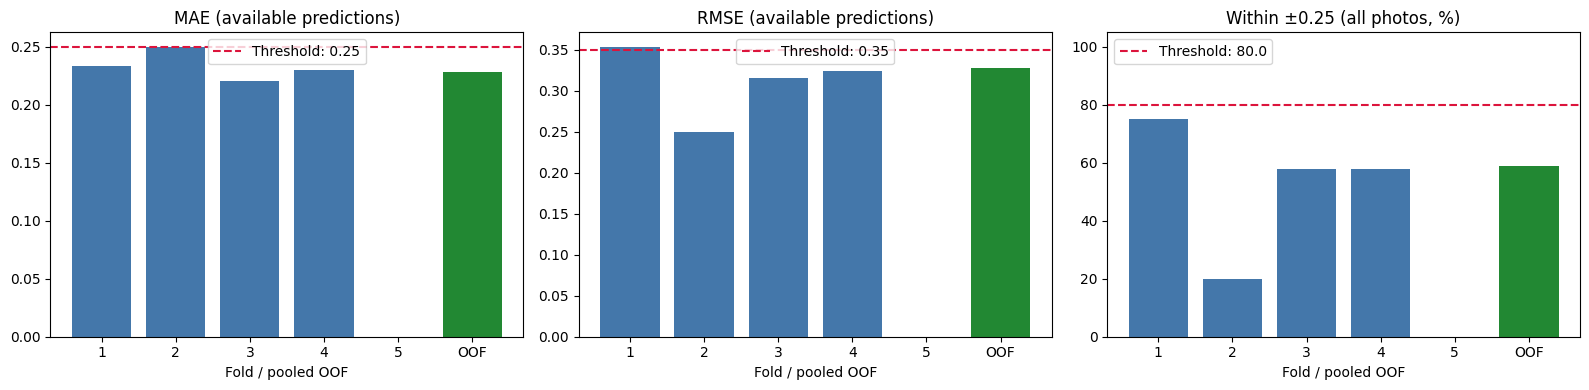

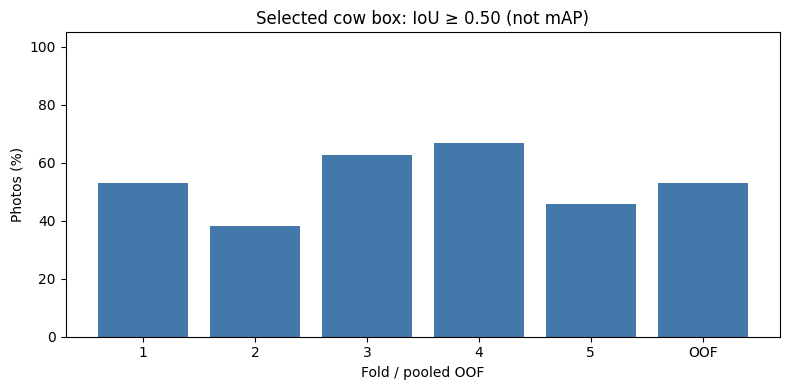

Reports saved to: /content/drive/MyDrive/lecheros/Dataset/bcs_training/evaluation_5fold_bcs


In [11]:
s=summary.query("scope == 'target_range' and mode == 'pipeline'").copy()
fig,axes=plt.subplots(1,3,figsize=(16,4))
for ax,col,limit,title in zip(axes,['MAE','RMSE','within_025_pct_all'],
                             [MAE_LIMIT,RMSE_LIMIT,HIT_LIMIT],
                             ['MAE (available predictions)','RMSE (available predictions)','Within ±0.25 (all photos, %)']):
    ax.bar(s.fold.astype(str),s[col],color=['#4477AA']*5+['#228833'])
    ax.axhline(limit,color='crimson',linestyle='--',label=f'Threshold: {limit}')
    ax.set(title=title,xlabel='Fold / pooled OOF')
    ax.set_ylim(bottom=0)
    if col.endswith('_all'): ax.set_ylim(0,105)
    ax.legend()
fig.tight_layout()
fig.savefig(OUT/'bcs_fold_comparison.png',dpi=180,bbox_inches='tight')
plt.show()

fig,ax=plt.subplots(figsize=(8,4))
ax.bar(det_summary.fold.astype(str),det_summary.selected_IoU_ge_050_pct,color='#4477AA')
ax.set(title='Selected cow box: IoU ≥ 0.50 (not mAP)',xlabel='Fold / pooled OOF',ylabel='Photos (%)',ylim=(0,105))
fig.tight_layout()
fig.savefig(OUT/'detector_fold_comparison.png',dpi=180,bbox_inches='tight')
plt.show()

summary.to_csv(OUT/'bcs_summary.csv',index=False)
det_summary.to_csv(OUT/'detector_summary.csv',index=False)
cows.to_csv(OUT/'cow_details.csv',index=False)
cow_summary.to_csv(OUT/'cow_mean_prediction_summary.csv',index=False)
fold_stats.to_csv(OUT/'fold_mean_std.csv')
baseline.to_csv(OUT/'fixed_midpoint_baseline.csv',index=False)
config=dict(target_range=TARGET_RANGE,tolerance=TOLERANCE,mae_limit=MAE_LIMIT,rmse_limit=RMSE_LIMIT,
            hit_limit=HIT_LIMIT,det_conf=DET_CONF,det_imgsz=DET_IMGSZ,cls_imgsz=CLS_IMGSZ,
            ultralytics_version=ultralytics.__version__,prediction_rule='top1 numeric BCS class',
            detector_paths={str(k):str(v) for k,v in DETECTOR_PATHS.items()},
            classifier_paths={str(k):str(v) if v else None for k,v in CLASSIFIER_PATHS.items()},
            manifest_sha256={str(k):hashlib.sha256(Path(v).read_bytes()).hexdigest() for k,v in MANIFEST_PATHS.items()})
(OUT/'evaluation_config.json').write_text(json.dumps(config,indent=2))
print('Reports saved to:',OUT)
if all(p is None for p in CLASSIFIER_PATHS.values()):
    print('Detector evaluation is complete. BCS criteria cannot be assessed until BCS classifiers are supplied.')
